# Customer Segmentation Analysis (RFM + K-Means)

**Goal:** Group customers by purchasing behaviour so each group can get a suitable marketing action.

**Dataset:** UCI "Online Retail" transactions (December 2010 to December 2011).

**Method:** Clean the data, build Recency, Frequency, and Monetary (RFM) features, scale them, choose the number of clusters with the Elbow Method, run K-Means, then profile each cluster.

In [30]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import datetime as dt
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [31]:
# Import dataset
df = pd.read_csv("C:/Users/PROGRESSIVE/Desktop/Oasis Internship/data.csv", encoding="latin1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [5]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

In [6]:
df.isna().sum(axis=0)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
df_raw = df.copy()  

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]  

In [9]:
print("Original data:", df_raw.shape)
print("Cleaned data:", df.shape)

Original data: (541909, 8)
Cleaned data: (530104, 8)


In [10]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,530104.000000,530104.000000,397884.000000
mean,10.542037,3.907625,15294.423453
std,155.524124,35.915681,1713.141560
min,1.000000,0.001000,12346.000000
25%,1.000000,1.250000,13969.000000
50%,3.000000,2.080000,15159.000000
75%,10.000000,4.130000,16795.000000
max,80995.000000,13541.330000,18287.000000


In [11]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

In [12]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [13]:
print(df["InvoiceDate"].dtype)
print(df_raw["InvoiceDate"].dtype)

datetime64[us]
str


In [14]:
df.dtypes

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

In [15]:
df["CustomerID"].isnull().sum()

np.int64(132220)

In [16]:
df_clean = df.copy()

In [17]:
df = df.dropna(subset=["CustomerID"])

In [18]:
print("Before:", df_clean.shape)
print("After:", df.shape)

Before: (530104, 8)
After: (397884, 8)


### Data Cleaning

- Removed returns and rows with a zero or negative quantity or price: **541,909 to 530,104 rows**.
- Removed rows with no customer ID (about 25%), since a purchase can't be assigned to a customer without one: **530,104 to 397,884 rows**.
- Converted `InvoiceDate` to a datetime type.
- The final RFM table has **4,338 customers**.

In [19]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [20]:
df[["Quantity", "UnitPrice", "TotalPrice"]].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [21]:
invoice_total = df.groupby("InvoiceNo")["TotalPrice"].sum()

In [22]:
average_purchase_value = invoice_total.mean()

print(average_purchase_value)

480.8659563997409


In [24]:
purchase_frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()
purchase_frequency.head()

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [25]:
customer_lifetime_value = df.groupby("CustomerID")["TotalPrice"].sum()
customer_lifetime_value.head()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
Name: TotalPrice, dtype: float64

In [26]:
customer_metrics = pd.DataFrame({
    "Purchase_Frequency": purchase_frequency,
    "Customer_Lifetime_Value": customer_lifetime_value
})

customer_metrics.head()

,Purchase_Frequency,Customer_Lifetime_Value
CustomerID,,
12346.0,1,77183.60
12347.0,7,4310.00
12348.0,4,1797.24
12349.0,1,1757.55
12350.0,1,334.40


### Descriptive Statistics: What I See

- The **average purchase value** (per invoice) is about **481**.
- A typical customer places about **4 orders** [check against your printed value].
- The **average customer lifetime value** is about **2,050** [check against your printed value].

### Engineer features to cluster

We have to build variables involving customers behaviour

**Recency**

low - recently

high - long time ago

**Frequency**

**Monetary**

In [40]:
# Total Purchase
df['total_price'] = df['UnitPrice'] * df['Quantity']
df = df[df['total_price'] > 0]
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,total_price
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [28]:
# Date - verify the most recent date
max(df['InvoiceDate']) # max date of purchase

Timestamp('2011-12-09 12:50:00')

In [33]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [34]:
df["InvoiceDate"].dtype

dtype('<M8[us]')

In [35]:
max(df['InvoiceDate']) + dt.timedelta(days=1)

Timestamp('2011-12-10 12:50:00')

In [36]:
end_date = max(df['InvoiceDate']) + dt.timedelta(days=1)

### Aggregated Table

In [65]:
df_rfm = df.groupby('CustomerID').agg(
    recency = ('InvoiceDate', lambda x: (end_date-x.max()).days),
    frequency = ('InvoiceNo', 'nunique'),
    monetary = ('total_price', 'sum')
)
df_rfm.head()

,recency,frequency,monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [66]:
df_rfm.isna().sum(axis=0)

recency      0
frequency    0
monetary     0
dtype: int64

### Data Exploration

In [67]:
df_rfm.monetary.mean()
df_rfm.shape

(4338, 3)

### Scaling: Standardisation

In [68]:
# Preprocessing data for KMeans clustering

df_log = np.log1p(df_rfm)

scaler = StandardScaler()

df_norm = scaler.fit_transform(df_log)

df_norm = pd.DataFrame(
    df_norm,
    columns=["recency", "frequency", "monetary"],
    index=df_rfm.index
)

df_norm.head()

,recency,frequency,monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.706225
12347.0,-2.038734,1.074425,1.411843
12348.0,0.373104,0.386304,0.716489
12349.0,-0.623086,-0.955214,0.698739
12350.0,1.424558,-0.955214,-0.618962


In [69]:
df_norm.describe()

,recency,frequency,monetary
count,4.338000e+03,4.338000e+03,4.338000e+03
mean,-8.025955e-17,-8.189750e-18,2.817274e-16
std,1.000115e+00,1.000115e+00,1.000115e+00
min,-2.341296e+00,-9.552143e-01,-4.004574e+00
25%,-6.613615e-01,-9.552143e-01,-6.856676e-01
50%,8.992557e-02,-3.615828e-01,-6.218718e-02
75%,8.447915e-01,6.532370e-01,6.541861e-01
max,1.564198e+00,5.858535e+00,4.731591e+00


Recency, frequency, and monetary values are heavily skewed, because a few customers order and spend far more than the rest. I applied a log transform to reduce the skew, then StandardScaler so that all three features are on the same scale before clustering.

### Elbow Method

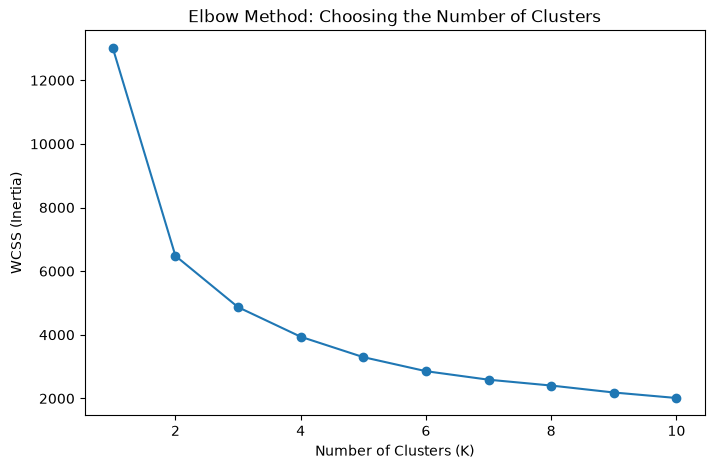

In [70]:
# Using Elbow method to determine the optimal number of cluster
wcss = []

for i in range (1,11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(df_norm)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow graph
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(range(1, 11), wcss, marker='o')

ax.set_title("Elbow Method: Choosing the Number of Clusters")
ax.set_xlabel("Number of Clusters (K)")
ax.set_ylabel("WCSS (Inertia)")

plt.show()

### Choosing the Number of Clusters

I ran K-Means for 1 to 10 clusters on the scaled RFM data and plotted the WCSS (inertia) for each.

- WCSS drops sharply from 1 to 2 clusters, then more gradually from 2 to 3 and 3 to 4. After about 4 clusters, the line flattens and each extra cluster improves little.
- There is no single sharp elbow, so I chose **K = 3** as a balance between fit and interpretability. Two clusters would only split customers into "good" and "bad," while three clusters give groups with clearly different behaviour: **High-Value**, **Regular**, and **At-Risk**.
- Going beyond 3 clusters gives smaller gains and more groups to describe and market to.

### K-Means Clustering

In [80]:
# Choosing the number of clusters based on the Elbow Method
optimal_k = 3

#K-Means Clustering
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
labels = kmeans.fit_predict(df_norm)

df_rfm['cluster'] = labels
df_rfm.head(10)

,recency,frequency,monetary,cluster
CustomerID,,,,
12346.0,326,1,77183.60,0
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,0
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,2
12352.0,36,8,2506.04,1
12353.0,204,1,89.00,2
12354.0,232,1,1079.40,2
12355.0,214,1,459.40,2


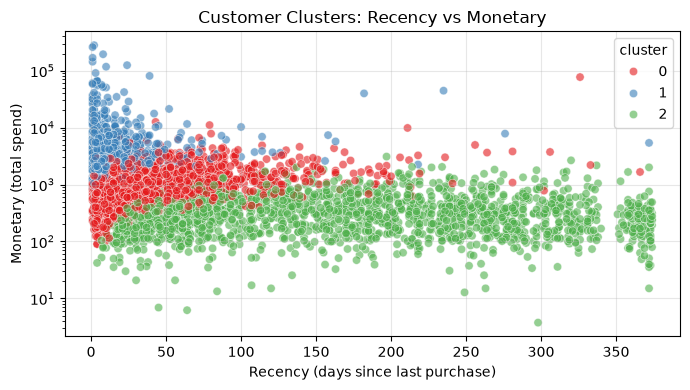

In [81]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df_rfm, x="recency", y="monetary", hue="cluster",
                palette="Set1", alpha=0.6, ax=ax)
ax.set_title("Customer Clusters: Recency vs Monetary")
ax.set_xlabel("Recency (days since last purchase)")
ax.set_ylabel("Monetary (total spend)")
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Clusters: Recency vs Monetary

- **Cluster 1 (High-Value)** sits at the top left: these customers bought recently (mostly within the last 60 days or so) and spend the most.
- **Cluster 2 (At-Risk)** is spread along the bottom with the lowest spend, and makes up most of the customers on the right side of the plot, who have not bought for a long time.
- **Cluster 0 (Regular)** sits in between, with moderate spend and mostly low to medium recency.
- The High-Value cluster is clearly separated at the top, but Regular and At-Risk overlap at low recency and moderate spend, so spend separates the groups better than recency does.
- Some At-Risk customers bought recently but spend very little, so not every customer in this group has drifted away.
- The spend axis uses a **log scale**, because a few customers spend far more than the rest.

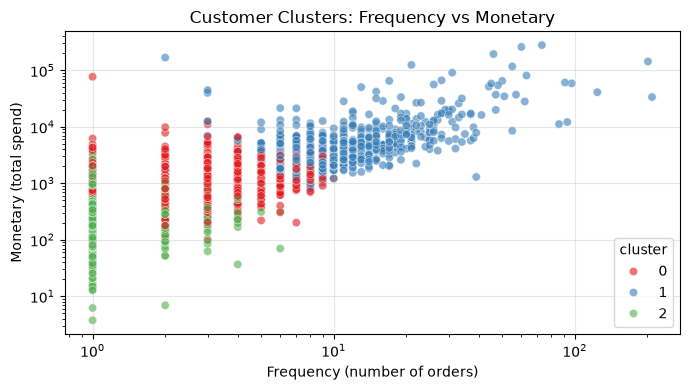

In [82]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df_rfm, x="frequency", y="monetary", hue="cluster",
                palette="Set1", alpha=0.6, ax=ax)
ax.set_title("Customer Clusters: Frequency vs Monetary")
ax.set_xlabel("Frequency (number of orders)")
ax.set_ylabel("Monetary (total spend)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Clusters: Frequency vs Monetary

- **Cluster 1 (High-Value)** sits in the upper right: these customers place the most orders (mostly 6 or more, some over 100) and spend the most. A few have only 2 to 3 orders but very large spend.
- **Cluster 2 (At-Risk)** sits at the lower left, mostly at 1 to 3 orders with the lowest spend, which means most of them bought only once or twice.
- **Cluster 0 (Regular)** sits in between, mostly at 2 to 8 orders with moderate spend of roughly 100 to 10,000.
- Spend rises with the number of orders, so customers who order more also tend to spend more.
- Clusters 0 and 2 overlap at low order counts, because they differ mainly in **recency** (how long ago they last bought), which is not shown on this plot. Clusters 0 and 1 also overlap a little at around 6 to 9 orders.
- One Regular customer placed a single order worth about 77,000, a very large one-off purchase, which is why they do not look like the rest of their group.
- The vertical stripes appear because the number of orders is always a whole number. Both axes use a **log scale**, because a few customers order and spend far more than the rest.

In [72]:
df_rfm["cluster"].value_counts().sort_index()

cluster
0    1696
1     776
2    1866
Name: count, dtype: int64

In [73]:
# Profiling the clusters
cluster_profile = df_rfm.groupby("cluster").agg(
    Customers=("cluster", "count"),
    Avg_Recency=("recency", "mean"),
    Avg_Frequency=("frequency", "mean"),
    Avg_Monetary=("monetary", "mean")
).round(2)

print(cluster_profile)

         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
cluster                                                     
0             1696        44.46           3.37       1257.69
1              776        17.07          13.27       7865.64
2             1866       167.61           1.35        361.54


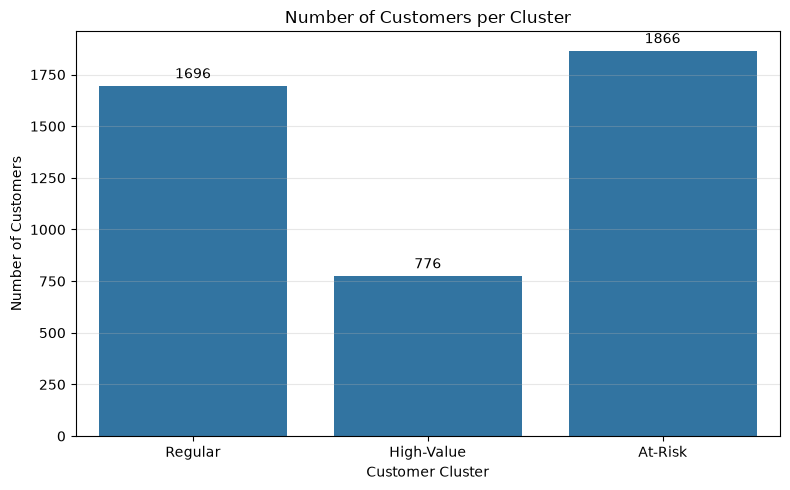

In [78]:
# Number of customers per cluster
cluster_counts = df_rfm["cluster"].value_counts().sort_index()

# Names for each cluster (based on your current profile table)
names = {0: "Regular", 1: "High-Value", 2: "At-Risk"}
labels = cluster_counts.index.map(names)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(x=labels, y=cluster_counts.values, ax=ax)
ax.bar_label(ax.containers[0], padding=3)

ax.set_title("Number of Customers per Cluster")
ax.set_xlabel("Customer Cluster")
ax.set_ylabel("Number of Customers")
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Customers per Cluster: What I See

- **At-Risk customers (Cluster 2)** are the largest group, with **1,866 customers (43.0%)**.
- **Regular customers (Cluster 0)** are next, with **1,696 customers (39.1%)**.
- **High-Value customers (Cluster 1)** are the smallest group, with **776 customers (17.9%)**, but they order most often and spend the most per customer.
- The tallest bar shows the group with the most customers, not the most valuable one. The largest group is the least valuable, and the most valuable group is the smallest.
- This means the business should focus on retaining the small High-Value group and on winning back the large At-Risk group.

## Marketing Insights and Recommendations

The analysis found three customer groups based on Recency (how recently they bought), Frequency (how many orders they placed), and Monetary value (how much they spent).

### Cluster 1: High-Value Customers (776 customers, 17.9%)
These customers bought most recently (about 17 days ago on average), place the most orders (about 13), and spend the most (about 7,866 on average). They are fewer than one in five customers, but they bring in roughly two thirds of total revenue, so losing them would hurt the business most.

**Recommendations:**
- Start a loyalty or VIP programme with early access to new products.
- Give them personalised recommendations and priority customer service.
- Reward them with perks other than deep discounts, since they already buy often at full price.

### Cluster 0: Regular Customers (1,696 customers, 39.1%)
These customers bought fairly recently (about 44 days ago), place about 3 orders, and spend a moderate amount (about 1,258). They are the group with the most room to grow.

**Recommendations:**
- Offer product bundles and minimum-spend offers to raise the value of each order.
- Send reminders and email campaigns to encourage repeat purchases.
- Aim to move these customers up into the High-Value group.

### Cluster 2: At-Risk Customers (1,866 customers, 43.0%)
This is the largest group, but the least valuable. These customers last bought about 168 days ago, have placed only about 1 to 2 orders, and spend the least (about 362 on average).

**Recommendations:**
- Send win-back emails with a limited-time offer.
- Offer a reason to come back, such as a discount on a second purchase.
- Survey a sample of these customers to find out why they stopped buying.

### Key Takeaway
The largest group (At-Risk) is the least valuable, and the most valuable group (High-Value) is the smallest. The business should protect the High-Value group, grow the Regular group, and run a low-cost win-back campaign for the At-Risk group.